<a href="https://colab.research.google.com/github/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A03_%D0%93%D0%BE%D1%80%D0%B0_%D0%A4%D0%86%D0%A24_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

https://colab.research.google.com/drive/1oss1run67NNQNv3NN29oxgN3Fpj6KSjE?usp=sharing

---



## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [ ]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [ ]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.
df = pd.read_csv('house_price_regression_dataset.csv')




### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [ ]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.





## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [ ]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.

display(df.head())
df.info()




,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [ ]:
# Ваш код:
# Порахуйте кількість дублікатів.
print("Кількість дублікованих рядків:", df.duplicated().sum())




Кількість дублікованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [ ]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.
print(df.isnull().sum())




Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [ ]:
# Ваш код:
# Отримайте описову статистику датасету.
display(df.describe())



,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [ ]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.
print(df['Neighborhood_Quality'].value_counts().sort_index())


Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

/tmp/ipykernel_2989/292502690.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')


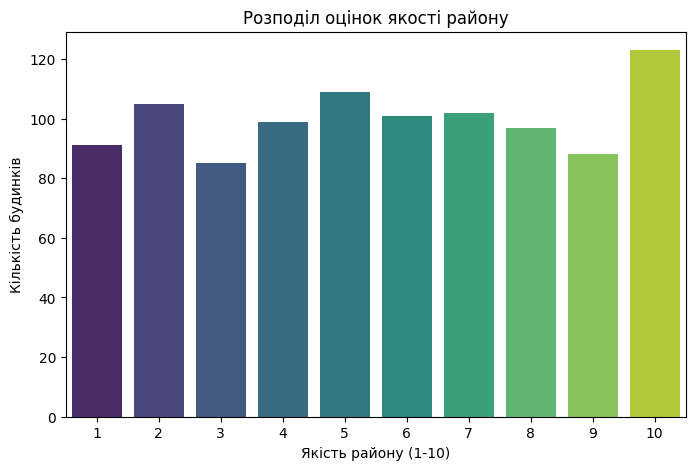

In [ ]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')
plt.title('Розподіл оцінок якості району')
plt.xlabel('Якість району (1-10)')
plt.ylabel('Кількість будинків')
plt.show()


### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [ ]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
print(df['Num_Bathrooms'].value_counts().sort_index())


Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

/tmp/ipykernel_2989/2839856486.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Num_Bathrooms', palette='muted')


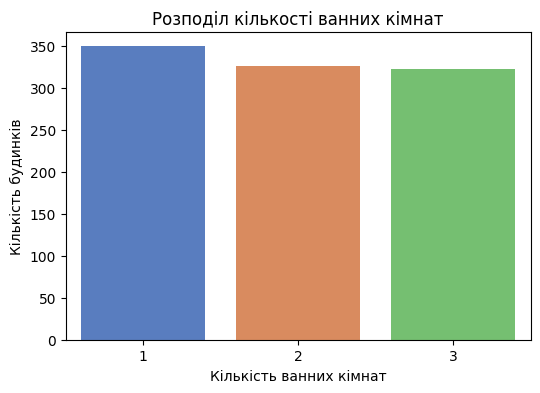

In [ ]:
# Ваш код:
# Побудуйте відповідну діаграму.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Num_Bathrooms', palette='muted')
plt.title('Розподіл кількості ванних кімнат')
plt.xlabel('Кількість ванних кімнат')
plt.ylabel('Кількість будинків')
plt.show()


### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

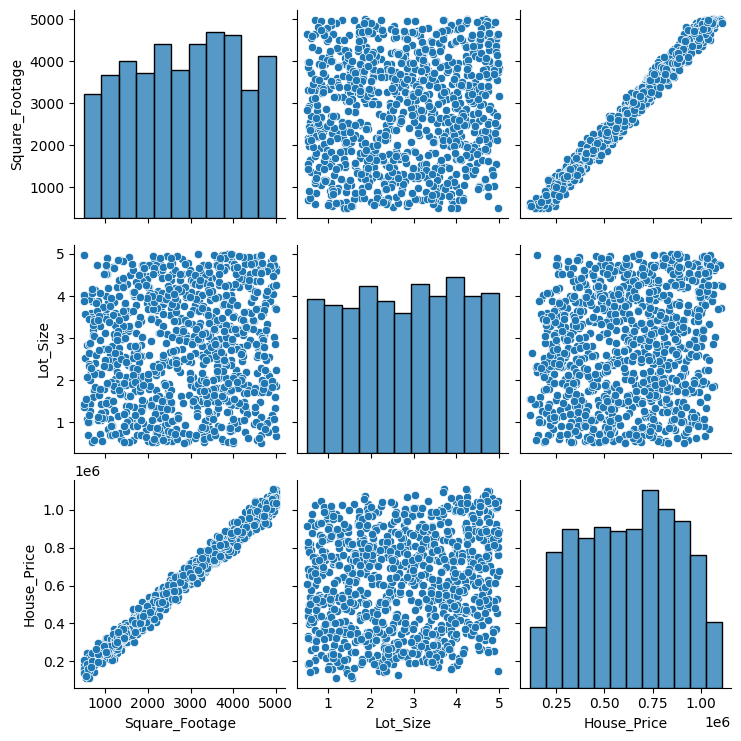

In [ ]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.
sns.pairplot(df[['Square_Footage', 'Lot_Size', 'House_Price']])
plt.show()



## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

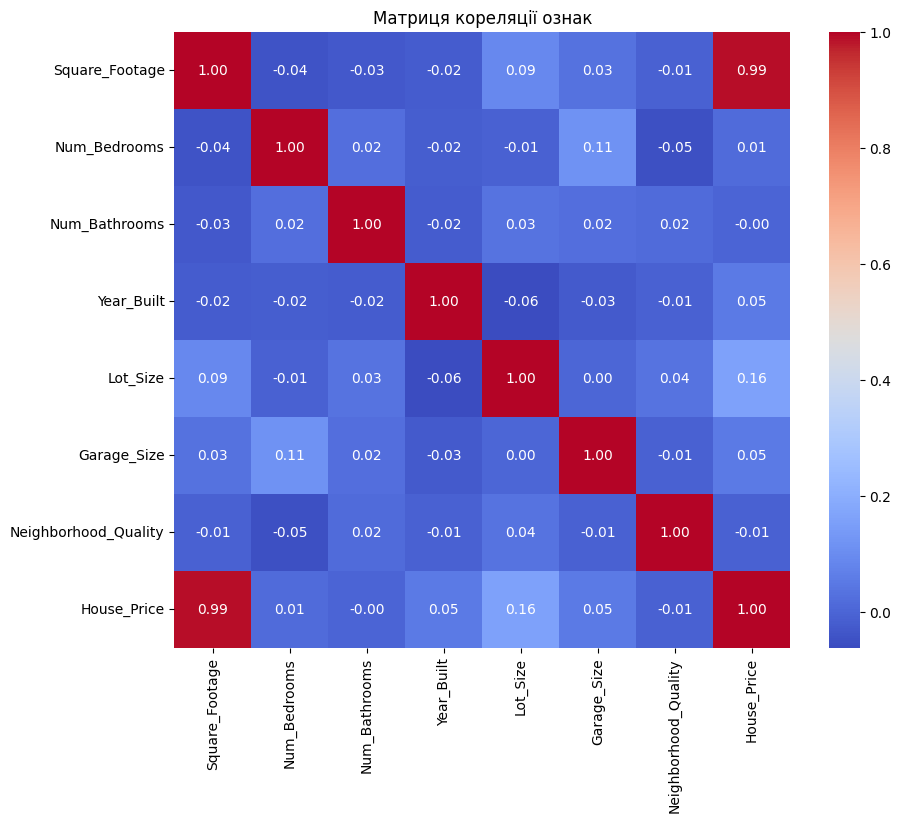

In [ ]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Матриця кореляції ознак')
plt.show()



### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [ ]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.
print(corr_matrix['House_Price'].sort_values(ascending=False))



House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [ ]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error



### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [ ]:
# Ваш код:
# Створіть `X` та `y`.
X = df.drop('House_Price', axis=1)
y = df['House_Price']



### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [ ]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [ ]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.
models = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    'Ridge': Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
    'Lasso': Pipeline([('scaler', StandardScaler()), ('lasso', Lasso())]),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}



### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [ ]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results[name] = {'R2': r2, 'MAE': mae, 'MSE': mse}
    print(f"{name}:\n R2: {r2:.4f}\n MAE: {mae:.2f}\n MSE: {mse:.2f}\n")



Linear Regression:
 R2: 0.9984
 MAE: 8174.58
 MSE: 101434798.51

Ridge:
 R2: 0.9984
 MAE: 8241.59
 MSE: 102480990.01

Lasso:
 R2: 0.9984
 MAE: 8174.75
 MSE: 101436558.18

Random Forest:
 R2: 0.9939
 MAE: 16114.29
 MSE: 394131747.45

Gradient Boosting:
 R2: 0.9965
 MAE: 12305.22
 MSE: 224965597.85



### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

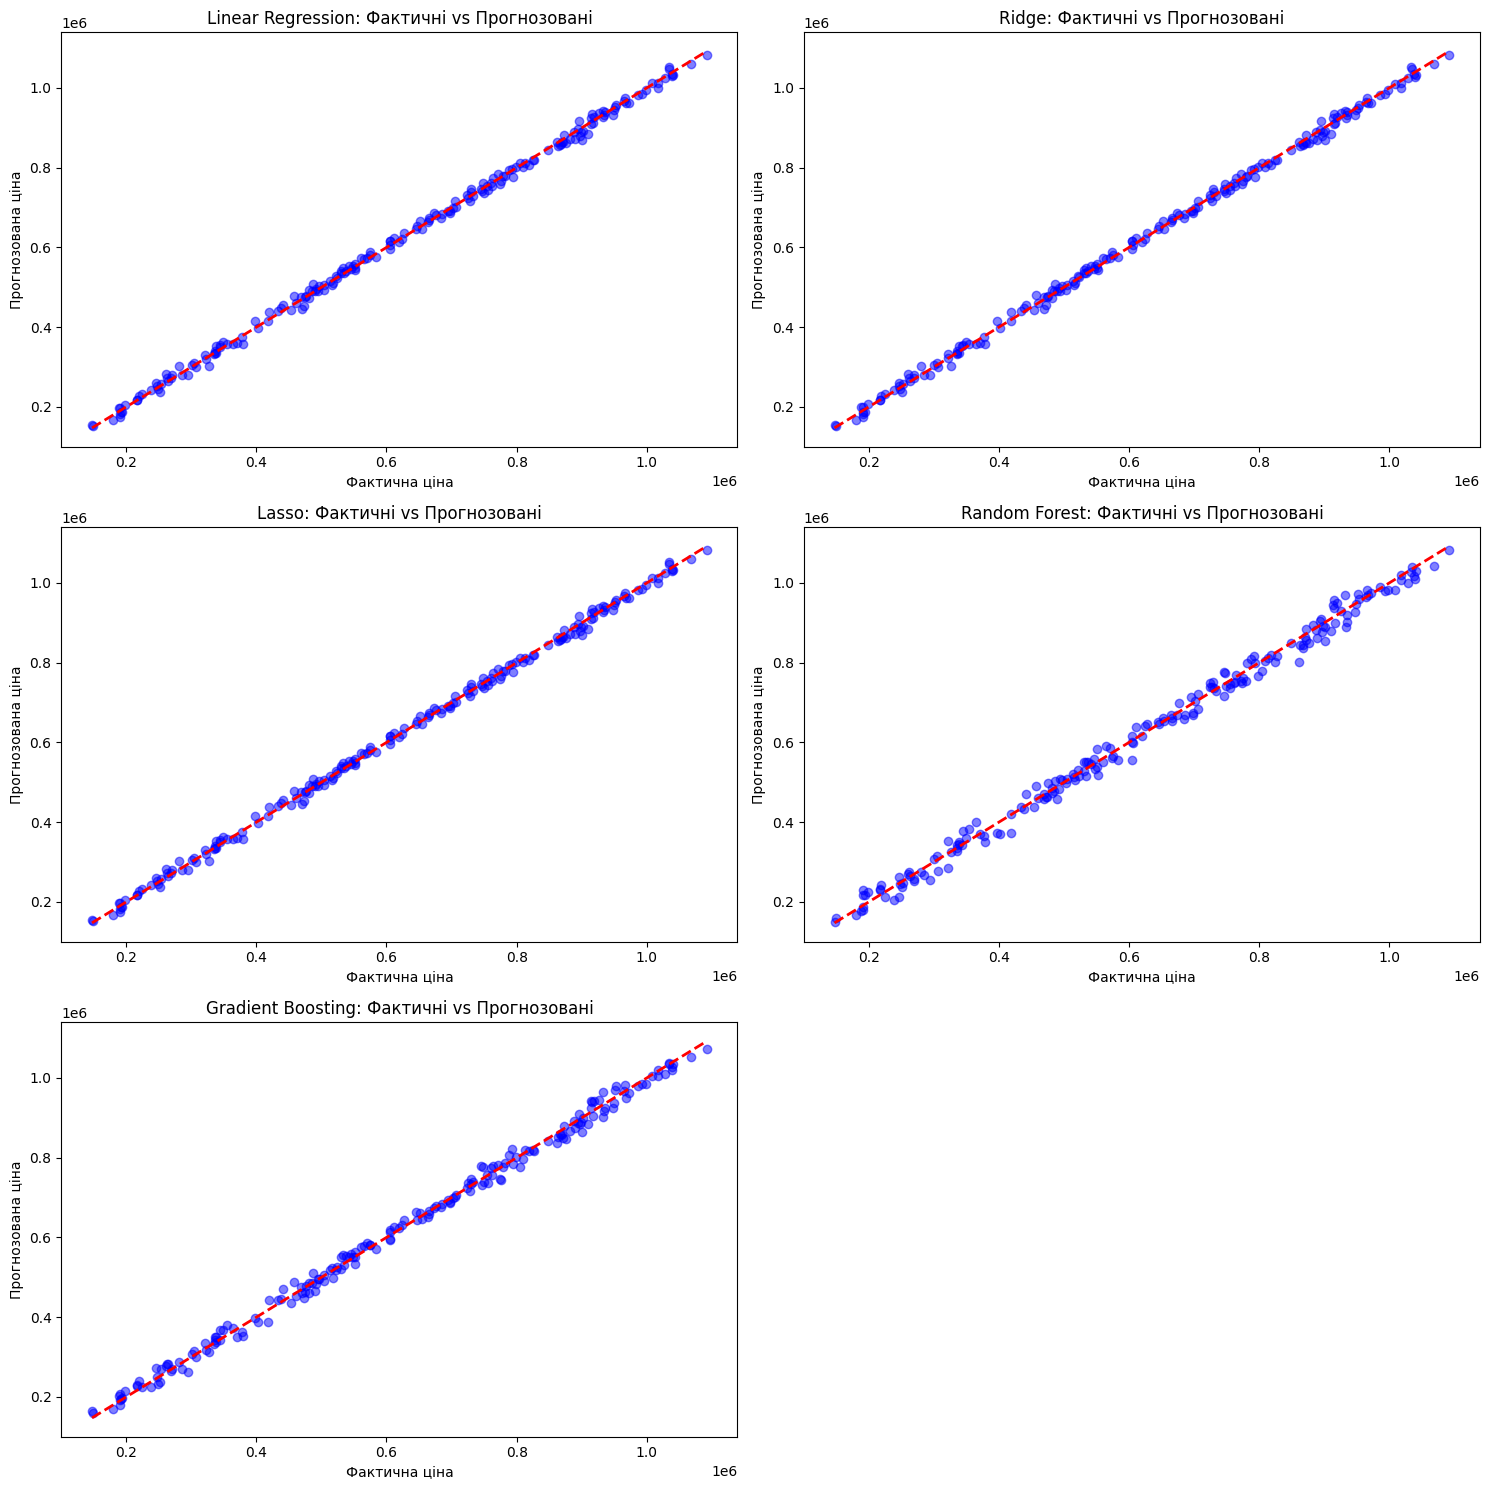

In [ ]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    ax = axes[i]
    ax.scatter(y_test, y_pred, alpha=0.5, color='b')
    # Лінія ідеального прогнозу
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_title(f'{name}: Фактичні vs Прогнозовані')
    ax.set_xlabel('Фактична ціна')
    ax.set_ylabel('Прогнозована ціна')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()



## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [28]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
param_grid = {
    'n_estimators': [50, 100],
    'max_features': ['sqrt', 1.0],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5]
}

rf = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Найкращі параметри: {grid_search.best_params_}")

Найкращі параметри: {'max_depth': 10, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 100}


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [29]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
best_rf = grid_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)

r2_best = r2_score(y_test, y_pred_best_rf)
mae_best = mean_absolute_error(y_test, y_pred_best_rf)
mse_best = mean_squared_error(y_test, y_pred_best_rf)

print(f"Оптимізований Random Forest:\n R2: {r2_best:.4f}\n MAE: {mae_best:.2f}\n MSE: {mse_best:.2f}")



Оптимізований Random Forest:
 R2: 0.9938
 MAE: 16073.02
 MSE: 397406424.17


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [30]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.
rf_comparison = pd.DataFrame({
    'Метрика': ['R2', 'MAE', 'MSE'],
    'Базова модель': [results['Random Forest']['R2'], results['Random Forest']['MAE'], results['Random Forest']['MSE']],
    'Оптимізована модель': [r2_best, mae_best, mse_best]
})
display(rf_comparison)



,Метрика,Базова модель,Оптимізована модель
0,R2,9.938855e-01,9.938347e-01
1,MAE,1.611429e+04,1.607302e+04
2,MSE,3.941317e+08,3.974064e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Після підбору параметрів якість моделі практично не змінилася (показник $R^2$ залишився на рівні 0.9938, а MAE трохи зменшилась з 16114 до 16073). Оскільки базова модель вже була дуже добре навчена на цих даних, значного покращення не відбулося. Використовувати оптимізовану модель доцільно, але в цьому конкретному випадку базова лінійна регресія все одно працює краще.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [31]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.
lr_model = models['Linear Regression']
y_pred_lr = lr_model.predict(X_test)

predictions_df = pd.DataFrame({
    'Фактична ціна': y_test,
    'Прогнозована ціна': y_pred_lr
})
predictions_df['Похибка у %'] = np.abs(predictions_df['Фактична ціна'] - predictions_df['Прогнозована ціна']) / predictions_df['Фактична ціна'] * 100

display(predictions_df.sample(10, random_state=42))



,Фактична ціна,Прогнозована ціна,Похибка у %
436,1.068538e+06,1.059729e+06,0.824406
899,1.943537e+05,1.878686e+05,3.336793
346,2.702306e+05,2.797158e+05,3.510031
60,9.860069e+05,9.819493e+05,0.411517
867,9.533397e+05,9.573829e+05,0.424111
432,9.145557e+05,9.097643e+05,0.523912
543,7.461677e+05,7.424691e+05,0.495678
361,6.467663e+05,6.544456e+05,1.187332
486,5.233231e+05,5.246054e+05,0.245045
277,1.008539e+06,1.011344e+06,0.278073


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

Побудовані моделі: Під час лабораторної роботи було побудовано п'ять моделей регресії: Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting.

---

Найкраща модель: Найкращі значення метрик показали лінійні моделі (Linear Regression, Lasso, Ridge) з $R^2 = 0.9984$ та найменшою середньою абсолютною похибкою ($MAE \approx 8174$).

---


Вплив гіперпараметрів: Підбір гіперпараметрів для Random Forest за допомогою
GridSearchCV лише незначно покращив модель, оскільки алгоритм уже давав високий результат на базових налаштуваннях.

---


Точність прогнозів: Прогнози на тестовій вибірці є дуже точними. Відхилення (похибка) для лінійної регресії в більшості випадків складає менше 1-3%.

---


Фактори впливу: Кореляційний аналіз показав, що найголовнішим фактором, який визначає ціну нерухомості в даному датасеті, є загальна житлова площа будинку (Square_Footage). Інші фактори, такі як розмір ділянки або рік побудови, мають значно менший вплив.

